# 05 · Identifying household energy assets from smart-meter data

Can a supplier tell, from the grid meter alone, when a household is charging an electric vehicle or how much its heat pump consumes? Residential 4 has sub-meters on its EV charger, heat pump and PV system, so the true asset behaviour is known and can be used as labels, while the models only see what a smart meter records: **hourly grid import and grid export**.

Two tasks:

1. **EV charging detection (classification).** Is the EV charging in this hour (more than 0.2 kWh)? EV charging occurs in about 9% of hours, so the classes are imbalanced.
2. **Heat-pump disaggregation (regression).** How many kWh did the heat pump use in this hour? An on/off label is not useful here because in winter the heat pump runs almost all the time and modulates its power.

Detection is treated as an offline task, as when a supplier analyses past meter data: features may use the meter readings a few hours before and after the hour being classified, but never the sub-meter readings.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score, brier_score_loss, precision_recall_curve,
                             mean_absolute_error)
from xgboost import XGBClassifier, XGBRegressor

# Okabe-Ito colours, L-frame axes, no grid
OI = {'black': '#000000', 'orange': '#E69F00', 'blue': '#0072B2', 'green': '#009E73', 'vermillion': '#D55E00', 'sky': '#56B4E9'}
plt.rcParams.update({'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 9, 'legend.fontsize': 7,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.8,
                     'xtick.direction': 'out', 'ytick.direction': 'out', 'axes.grid': False,
                     'savefig.dpi': 300, 'savefig.bbox': 'tight'})
def panel(ax, letter):
    ax.text(-0.14, 1.04, letter, transform=ax.transAxes, fontsize=11, fontweight='bold', va='bottom')

## 1 · Hourly energy from cumulative meter readings

The raw data are cumulative readings. Re-indexing to a strict hourly grid before differencing means an hourly value only exists where two consecutive readings are exactly one hour apart, so no increment spans a data gap.

In [2]:
raw = pd.read_csv('../data/household_data_60min_singleindex_filtered.csv', parse_dates=['utc_timestamp']).set_index('utc_timestamp')
cols = ['ev', 'heat_pump', 'pv', 'grid_import', 'grid_export']
cum = raw[['DE_KN_residential4_' + c for c in cols]]
cum.columns = cols
hourly = cum.asfreq('h').diff().dropna()          # NaN wherever either reading is missing
print(f'{len(hourly):,} valid hours, {hourly.index.min():%Y-%m-%d} to {hourly.index.max():%Y-%m-%d}')
hourly.describe().round(3)

12,238 valid hours, 2015-10-13 to 2017-03-06


,ev,heat_pump,pv,grid_import,grid_export
count,12238.000,12238.000,12238.000,12238.000,12238.000
mean,0.117,0.386,1.058,0.554,0.809
std,0.418,0.435,1.919,0.576,1.662
min,0.000,0.000,0.000,0.000,0.000
25%,0.000,0.000,0.000,0.135,0.000
50%,0.000,0.355,0.000,0.370,0.000
75%,0.000,0.630,1.126,0.840,0.569
max,3.160,2.662,8.495,4.898,8.057


## 2 · Features a smart meter can provide

Only grid import and export are used: current values, the three hours before and after, the step change, 24-hour rolling statistics, the 24-hour export total (a proxy for sunny days, since the PV is behind the meter) and calendar terms.

In [3]:
def meter_features(h):
    grid = h[['grid_import', 'grid_export']].asfreq('h')   # keep the real time axis for shifts and windows
    imp, exp = grid.grid_import, grid.grid_export
    f = pd.DataFrame({'imp': imp, 'exp': exp, 'net': imp - exp})
    for k in (1, 2, 3):
        f[f'imp_lag{k}'] = imp.shift(k)
        f[f'imp_lead{k}'] = imp.shift(-k)
    f['d_imp'] = imp - imp.shift(1)
    roll = imp.rolling(24, min_periods=12)
    f['imp_24_mean'], f['imp_24_max'], f['imp_24_std'] = roll.mean(), roll.max(), roll.std()
    f['exp_24_sum'] = exp.rolling(24, min_periods=12).sum()
    f = f.reindex(h.index)
    local = h.index.tz_convert('Europe/Berlin')
    f['hour_sin'], f['hour_cos'] = np.sin(2*np.pi*local.hour/24), np.cos(2*np.pi*local.hour/24)
    f['month_sin'], f['month_cos'] = np.sin(2*np.pi*local.month/12), np.cos(2*np.pi*local.month/12)
    f['weekend'] = (local.dayofweek >= 5).astype(int)
    return f

X = meter_features(hourly)
n = len(X)
i_val, i_test = int(0.70*n), int(0.85*n)                 # chronological 70/15/15, as in notebooks 02-04
tr, va, te = slice(0, i_val), slice(i_val, i_test), slice(i_test, n)
X = X.fillna(X.iloc[tr].median())                         # medians from the training set only
print('train:', X.index[0].date(), 'to', X.index[i_val-1].date())
print('val:  ', X.index[i_val].date(), 'to', X.index[i_test-1].date())
print('test: ', X.index[i_test].date(), 'to', X.index[-1].date())

train: 2015-10-13 to 2016-10-04
val:   2016-10-04 to 2016-12-20
test:  2016-12-20 to 2017-03-06


## 3 · EV charging detection

Three detectors of increasing complexity: a rule on grid import alone, logistic regression and gradient-boosted trees (XGBoost). Each decision threshold is chosen on the validation set to maximise F1, then applied unchanged to the test set. XGBoost is trained with five seeds to show how stable the result is.

In [4]:
y = (hourly.ev > 0.2).astype(int).values
print(f'EV charging hours: train {y[tr].mean():.1%}, test {y[te].mean():.1%}')

def best_threshold(y_true, score, grid):
    return max(grid, key=lambda t: f1_score(y_true, score > t))

def scores(y_true, pred, prob=None):
    out = {'precision': precision_score(y_true, pred), 'recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred)}
    if prob is not None:
        out.update({'PR-AUC': average_precision_score(y_true, prob), 'ROC-AUC': roc_auc_score(y_true, prob)})
    return out

results, probs = {}, {}
# 1) rule: grid import above a threshold
t_rule = best_threshold(y[va], X.imp.values[va], np.arange(0.2, 4.0, 0.05))
results['Rule on import'] = scores(y[te], X.imp.values[te] > t_rule, X.imp.values[te])
probs['Rule on import'] = X.imp.values[te]

# 2) logistic regression
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X.iloc[tr], y[tr])
t_lr = best_threshold(y[va], logreg.predict_proba(X.iloc[va])[:, 1], np.arange(0.05, 0.95, 0.01))
p_lr = logreg.predict_proba(X.iloc[te])[:, 1]
results['Logistic regression'] = scores(y[te], p_lr > t_lr, p_lr) | {'Brier': brier_score_loss(y[te], p_lr)}
probs['Logistic regression'] = p_lr

# 3) XGBoost, five seeds
runs = []
for seed in range(5):
    xgb = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8,
                        colsample_bytree=0.8, eval_metric='logloss', random_state=seed).fit(X.iloc[tr], y[tr])
    t_x = best_threshold(y[va], xgb.predict_proba(X.iloc[va])[:, 1], np.arange(0.05, 0.95, 0.01))
    p_x = xgb.predict_proba(X.iloc[te])[:, 1]
    runs.append(scores(y[te], p_x > t_x, p_x) | {'Brier': brier_score_loss(y[te], p_x)})
    if seed == 0:
        probs['XGBoost'], xgb0, t_x0 = p_x, xgb, t_x
runs = pd.DataFrame(runs)
results['XGBoost (mean of 5 seeds)'] = runs.mean().to_dict()

table = pd.DataFrame(results).T[['precision', 'recall', 'F1', 'PR-AUC', 'ROC-AUC', 'Brier']]
print('XGBoost standard deviation over seeds:', runs.std().round(3).to_dict())
table.round(3)

EV charging hours: train 8.2%, test 10.7%


XGBoost standard deviation over seeds: {'precision': 0.038, 'recall': 0.026, 'F1': 0.018, 'PR-AUC': 0.004, 'ROC-AUC': 0.001, 'Brier': 0.001}


,precision,recall,F1,PR-AUC,ROC-AUC,Brier
Rule on import,0.365,0.655,0.469,0.432,0.737,NaN
Logistic regression,0.594,0.655,0.623,0.708,0.921,0.056
XGBoost (mean of 5 seeds),0.565,0.791,0.658,0.776,0.954,0.051


**Uncertainty.** A detector is only useful if its probabilities can be trusted. The Brier score above and the reliability diagram below compare predicted probabilities with how often charging actually occurred.

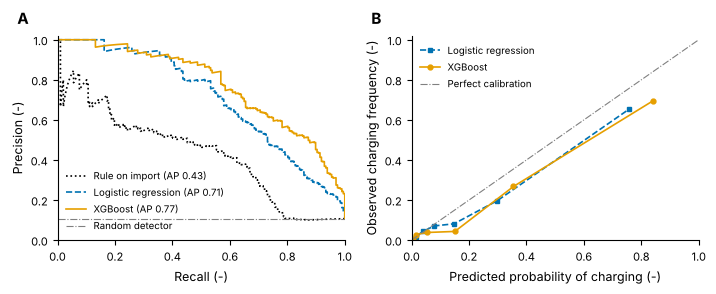

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
style = {'Rule on import': (OI['black'], ':'), 'Logistic regression': (OI['blue'], '--'), 'XGBoost': (OI['orange'], '-')}
for name, p in probs.items():
    prec, rec, _ = precision_recall_curve(y[te], p)
    c, ls = style[name]
    axes[0].plot(rec, prec, color=c, ls=ls, lw=1.2, label=f'{name} (AP {average_precision_score(y[te], p):.2f})')
axes[0].axhline(y[te].mean(), color='grey', lw=0.8, ls='-.', label='Random detector')
axes[0].set(xlabel='Recall (-)', ylabel='Precision (-)', xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(frameon=False, loc='lower left')
panel(axes[0], 'A')

for name in ['Logistic regression', 'XGBoost']:
    frac, mean_p = calibration_curve(y[te], probs[name], n_bins=10, strategy='quantile')
    c, ls = style[name]
    axes[1].plot(mean_p, frac, color=c, ls=ls, marker='o' if name == 'XGBoost' else 's', ms=3.5, lw=1.2, label=name)
axes[1].plot([0, 1], [0, 1], color='grey', lw=0.8, ls='-.', label='Perfect calibration')
axes[1].set(xlabel='Predicted probability of charging (-)', ylabel='Observed charging frequency (-)', xlim=(0, 1), ylim=(0, 1.02))
axes[1].legend(frameon=False, loc='upper left')
panel(axes[1], 'B')
fig.tight_layout()
fig.savefig('../figures/ev_detection_performance.png')
plt.show()

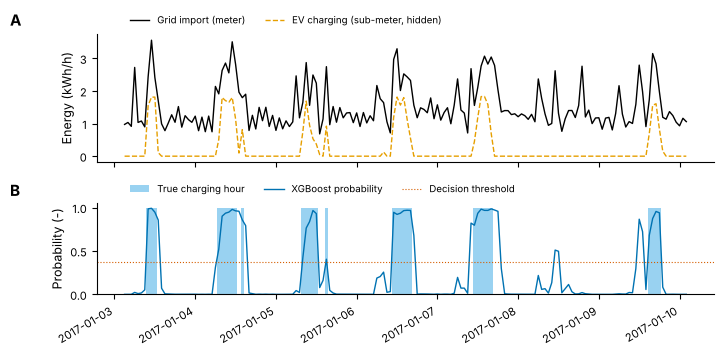

In [6]:
# One test week: what the meter sees, when the EV actually charged, and what the detector inferred
week = slice(i_test + 24*14, i_test + 24*21)
idx = X.index[week]
fig, axes = plt.subplots(2, 1, figsize=(7.2, 3.6), sharex=True, gridspec_kw={'height_ratios': [1.4, 1]})
axes[0].plot(idx, hourly.grid_import.values[week], color=OI['black'], lw=1, label='Grid import (meter)')
axes[0].plot(idx, hourly.ev.values[week], color=OI['orange'], lw=1, ls='--', label='EV charging (sub-meter, hidden)')
axes[0].set_ylabel('Energy (kWh/h)')
axes[0].legend(frameon=False, loc='lower left', bbox_to_anchor=(0.04, 1.0), ncol=2)
panel(axes[0], 'A')
axes[1].fill_between(idx, 0, y[week], step='mid', color=OI['sky'], alpha=0.6, lw=0, label='True charging hour')
axes[1].plot(idx, probs['XGBoost'][24*14:24*21], color=OI['blue'], lw=1, label='XGBoost probability')
axes[1].axhline(t_x0, color=OI['vermillion'], lw=0.8, ls=':', label='Decision threshold')
axes[1].set(ylabel='Probability (-)', ylim=(0, 1.05))
axes[1].legend(frameon=False, loc='lower left', bbox_to_anchor=(0.04, 1.0), ncol=3)
panel(axes[1], 'B')
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig('../figures/ev_detection_week.png')
plt.show()

In [7]:
imp = pd.Series(xgb0.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(8).round(3)

hour_cos    0.248
hour_sin    0.080
imp         0.072
imp_lag1    0.067
weekend     0.056
net         0.050
exp         0.049
d_imp       0.037
dtype: float32

The most important features are the hour of day and the import level and its change. The detector therefore combines the physical signature of charging (a sustained rise in import of about 2 kWh/h) with this household's habit of charging at similar times. Across many homes the habit part would differ from home to home, which is one reason a model trained on one household should not be expected to generalise.

## 4 · Heat-pump disaggregation

The target is the heat pump's hourly consumption. The baseline is the average consumption for each month and hour of day in the training data, which is what a supplier could estimate from typical profiles without any meter analysis.

In [8]:
y_hp = hourly.heat_pump.values
local = hourly.index.tz_convert('Europe/Berlin')
key = pd.Series(list(zip(local.month, local.hour)), index=hourly.index)
profile = pd.Series(y_hp[tr], index=key.iloc[tr]).groupby(level=0).mean()
base_te = key.iloc[te].map(profile).fillna(y_hp[tr].mean()).values

hp_runs = []
for seed in range(5):
    reg = XGBRegressor(n_estimators=500, max_depth=4, learning_rate=0.05, subsample=0.8,
                       colsample_bytree=0.8, random_state=seed).fit(X.iloc[tr], y_hp[tr])
    est = np.clip(reg.predict(X.iloc[te]), 0, None)
    hp_runs.append(mean_absolute_error(y_hp[te], est))
    if seed == 0:
        est0 = est
mae_base = mean_absolute_error(y_hp[te], base_te)
hp_table = pd.DataFrame({
    'MAE (kWh/h)': [mae_base, np.mean(hp_runs)],
    'MAE std over seeds': [np.nan, np.std(hp_runs)],
    'Test-period energy error (%)': [100*(base_te.sum()/y_hp[te].sum()-1), 100*(est0.sum()/y_hp[te].sum()-1)]},
    index=['Month-hour profile', 'XGBoost on meter features'])
print(f'MAE reduction vs profile: {100*(1-np.mean(hp_runs)/mae_base):.0f}%')
hp_table.round(3)

MAE reduction vs profile: 43%


,MAE (kWh/h),MAE std over seeds,Test-period energy error (%)
Month-hour profile,0.279,NaN,-24.240
XGBoost on meter features,0.160,0.003,-9.887


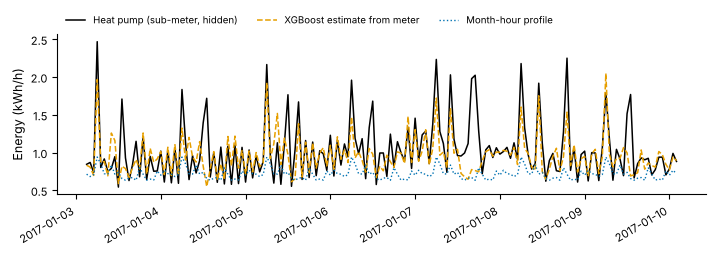

In [9]:
fig, ax = plt.subplots(figsize=(7.2, 2.6))
ax.plot(idx, y_hp[week], color=OI['black'], lw=1.1, label='Heat pump (sub-meter, hidden)')
ax.plot(idx, est0[24*14:24*21], color=OI['orange'], lw=1.1, ls='--', label='XGBoost estimate from meter')
ax.plot(idx, base_te[24*14:24*21], color=OI['blue'], lw=1, ls=':', label='Month-hour profile')
ax.set_ylabel('Energy (kWh/h)')
ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(0.0, 1.0), ncol=3)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig('../figures/heat_pump_disaggregation_week.png')
plt.show()

## 5 · Limitations

- **One household.** The models learn this home's habits. Identifying assets across many homes would need training on many households and testing on unseen ones, which this dataset cannot provide.
- **Seasonal test period.** The chronological test set covers December to March, so heat-pump results describe winter operation only.
- **No weather data.** Outdoor temperature would be the strongest heat-pump feature and is not used here; month and hour stand in for it.
- **Hourly resolution.** Charging sessions shorter than an hour, or at low power, are hard to separate from other large loads such as the dishwasher.